In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RUTA_DIAGNOSTICOS = "Diagnostics.xlsx"  

---
## Punto 2. Análisis estadístico de *Diagnostics.xlsx*

**Qué se hace:**
1. Se carga el archivo y se revisa qué contiene.
2. Se responde cada pregunta con tablas, gráficas y una prueba estadística sencilla:
   - **chi-cuadrado** para el género;
   - **Kruskal-Wallis** para la edad.
3. Se escoge el subconjunto de datos para los siguientes puntos.

### 2.0 Carga y descripción general

In [2]:
df = pd.read_excel(RUTA_DIAGNOSTICOS)

print("Número de registros y columnas:", df.shape)
print("Valores faltantes:", df.isna().sum().sum())
df.head()

Número de registros y columnas: (10646, 16)
Valores faltantes: 0


,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354


In [3]:
# Significado de las abreviaturas de los ritmos
nombres = {
    "SB": "Bradicardia sinusal",
    "SR": "Ritmo sinusal",
    "AFIB": "Fibrilación auricular",
    "ST": "Taquicardia sinusal",
    "SVT": "Taquicardia supraventricular",
    "AF": "Flutter auricular",
    "SA": "Irregularidad sinusal",
    "AT": "Taquicardia auricular",
    "AVNRT": "Taquicardia por reentrada nodal AV",
    "AVRT": "Taquicardia por reentrada AV",
    "SAAWR": "Marcapasos auricular migratorio",
}

# Estadística descriptiva de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PatientAge,10646.0,59.186831,18.030019,4.0,49.0,62.0,72.0,98.0
VentricularRate,10646.0,84.136107,34.455349,34.0,57.0,73.0,104.0,263.0
AtrialRate,10646.0,92.577870,60.093940,0.0,57.0,72.0,106.0,535.0
QRSDuration,10646.0,90.989292,17.479540,18.0,80.0,88.0,98.0,256.0
QTInterval,10646.0,384.150855,59.226289,114.0,344.0,390.0,426.0,736.0
QTCorrected,10646.0,434.154048,39.354182,219.0,408.0,430.0,456.0,760.0
RAxis,10646.0,39.620609,41.212648,-89.0,14.0,46.0,68.0,270.0
TAxis,10646.0,44.637704,57.478092,-89.0,19.0,42.0,62.0,270.0
QRSCount,10646.0,13.839470,5.676339,5.0,9.0,12.0,17.0,40.0
QOnset,10646.0,219.260567,6.410413,159.0,216.0,219.0,224.0,240.0


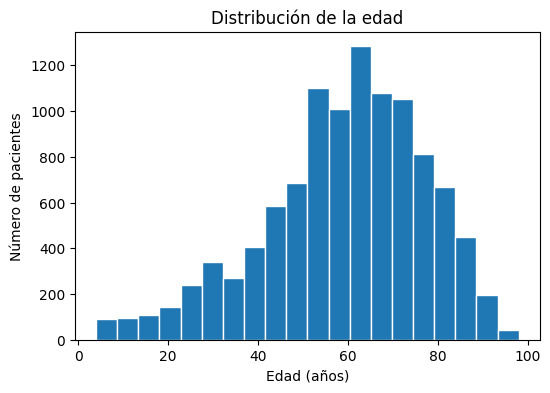

Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64
Porcentaje de hombres: 55.9 %


In [4]:
def graficar_barras(etiquetas, valores, titulo, etiqueta_y):
    """Gráfica de barras con el valor escrito encima de cada barra."""
    plt.figure(figsize=(10, 4))
    plt.bar(etiquetas, valores)
    for i in range(len(valores)):
        plt.text(i, valores[i], f"{valores[i]:.1f}", ha="center", va="bottom", fontsize=9)
    plt.title(titulo)
    plt.ylabel(etiqueta_y)
    plt.show()


plt.figure(figsize=(6, 4))
plt.hist(df["PatientAge"], bins=20, edgecolor="white")
plt.title("Distribución de la edad")
plt.xlabel("Edad (años)")
plt.ylabel("Número de pacientes")
plt.show()

genero = df["Gender"].value_counts()
print(genero)
print("Porcentaje de hombres:", round(100 * genero["MALE"] / len(df), 1), "%")

**Descripción general.**
- La base tiene **10.646 pacientes** y **16 variables**, sin valores faltantes.
- Las variables principales son:
  - `Rhythm`: el ritmo, con 11 clases;
  - `Beat`: condiciones adicionales;
  - `PatientAge` y `Gender`: datos del paciente;
  - mediciones del ECG: frecuencias, QRS, QT, ejes.
- La edad va de 4 a 98 años, con mediana de 62.
- El 55,9 % de los pacientes son hombres y el 44,1 % mujeres.


### 2.1 ¿Qué tipo de arritmias son más prevalentes?

           n      %                              Nombre
Rhythm                                                 
SB      3889  36.53                 Bradicardia sinusal
SR      1826  17.15                       Ritmo sinusal
AFIB    1780  16.72               Fibrilación auricular
ST      1568  14.73                 Taquicardia sinusal
SVT      587   5.51        Taquicardia supraventricular
AF       445   4.18                   Flutter auricular
SA       399   3.75               Irregularidad sinusal
AT       121   1.14               Taquicardia auricular
AVNRT     16   0.15  Taquicardia por reentrada nodal AV
AVRT       8   0.08        Taquicardia por reentrada AV
SAAWR      7   0.07     Marcapasos auricular migratorio


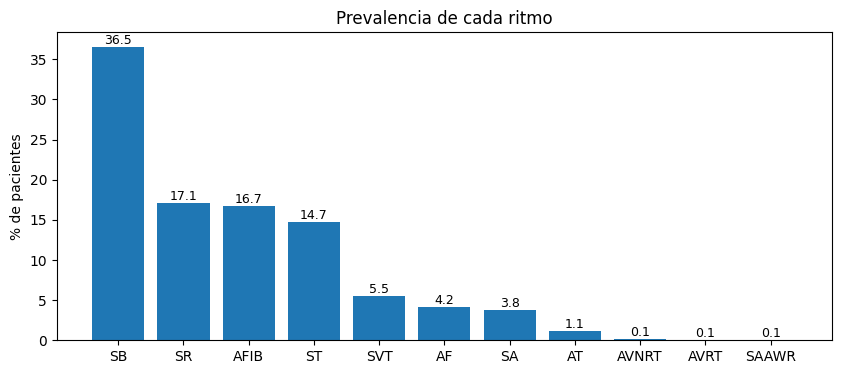

In [5]:
def prevalencia(df):
    """Número de pacientes y porcentaje de cada ritmo."""
    conteo = df["Rhythm"].value_counts()
    porcentaje = 100 * conteo / len(df)
    tabla = pd.DataFrame({"n": conteo, "%": porcentaje.round(2)})
    tabla["Nombre"] = [nombres[r] for r in tabla.index]
    return tabla


tabla_prev = prevalencia(df)
print(tabla_prev)
graficar_barras(tabla_prev.index, tabla_prev["%"].values, "Prevalencia de cada ritmo", "% de pacientes")

**Respuesta.**
- La arritmia más frecuente es la **bradicardia sinusal (SB, 36,5 %)**.
- Le siguen el ritmo sinusal normal (SR, 17,2 %), la **fibrilación auricular (AFIB, 16,7 %)** y la **taquicardia sinusal (ST, 14,7 %)**.
- Los ritmos AVNRT, AVRT y SAAWR tienen menos de 20 pacientes cada uno. Es decir, la base está **desbalanceada**.


### 2.2 ¿Hay arritmias más prevalentes para un género específico?
Para cada ritmo se compara el **% de hombres** con el % de hombres de toda la base (55,9 %). Luego se aplica una **prueba chi-cuadrado** entre ese ritmo y el resto de la base:
- si **p < 0,05**, la diferencia de género en ese ritmo es estadísticamente significativa.

Solo se prueban los ritmos con 30 pacientes o más, porque con muy pocos datos la prueba chi-cuadrado no es confiable.


In [6]:
def prueba_genero(df, ritmo):
    """Chi-cuadrado de una tabla 2x2: (este ritmo vs el resto) x (hombres vs mujeres)."""
    es_ritmo = df["Rhythm"] == ritmo
    tabla = pd.crosstab(es_ritmo, df["Gender"])
    chi2, p, gl, esperados = stats.chi2_contingency(tabla)
    return p


pct_hombres_total = 100 * (df["Gender"] == "MALE").mean()
filas = []
for ritmo in tabla_prev.index:
    datos_ritmo = df[df["Rhythm"] == ritmo]
    pct_hombres = 100 * (datos_ritmo["Gender"] == "MALE").mean()
    if len(datos_ritmo) >= 30:
        p = prueba_genero(df, ritmo)
    else:
        p = np.nan                      # muy pocos datos para la prueba
    filas.append([ritmo, len(datos_ritmo), round(pct_hombres, 1), round(100 - pct_hombres, 1), p])

tabla_genero = pd.DataFrame(filas, columns=["Ritmo", "n", "% hombres", "% mujeres", "p-valor"])
print(f"% de hombres en toda la base: {pct_hombres_total:.1f} %")
tabla_genero

% de hombres en toda la base: 55.9 %


,Ritmo,n,% hombres,% mujeres,p-valor
0,SB,3889,63.8,36.2,4.511473e-35
1,SR,1826,43.9,56.1,7.820535e-30
2,AFIB,1780,58.5,41.5,1.945825e-02
3,ST,1568,51.0,49.0,1.852296e-05
4,SVT,587,47.5,52.5,2.881532e-05
5,AF,445,57.8,42.2,4.619862e-01
6,SA,399,55.9,44.1,1.000000e+00
7,AT,121,52.9,47.1,5.563121e-01
8,AVNRT,16,25.0,75.0,NaN
9,AVRT,8,62.5,37.5,NaN


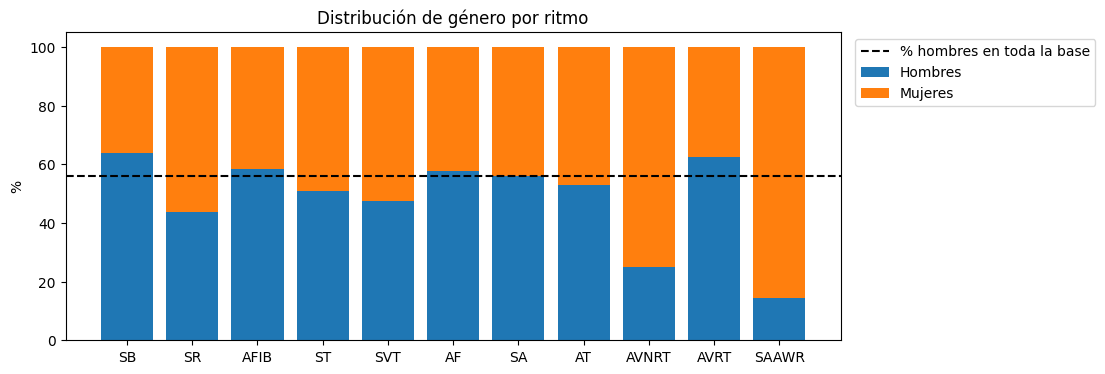

In [7]:
plt.figure(figsize=(10, 4))
plt.bar(tabla_genero["Ritmo"], tabla_genero["% hombres"], label="Hombres")
plt.bar(tabla_genero["Ritmo"], tabla_genero["% mujeres"], bottom=tabla_genero["% hombres"], label="Mujeres")
plt.axhline(pct_hombres_total, color="black", linestyle="--", label="% hombres en toda la base")
plt.title("Distribución de género por ritmo")
plt.ylabel("%")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

**Respuesta.** Sí hay ritmos con predominio de un género, con p < 0,05 en todos estos casos:
- **Más frecuentes en hombres:**
  - bradicardia sinusal (SB, 63,8 % hombres);
  - fibrilación auricular (AFIB, 58,5 % hombres). En este caso la diferencia es pequeña (p ≈ 0,02).
- **Más frecuentes en mujeres:**
  - taquicardia sinusal (ST);
  - taquicardia supraventricular (SVT, 52,5 % mujeres);
  - ritmo sinusal normal (SR, 56 % mujeres).
- **Sin diferencia significativa:** flutter (AF), irregularidad sinusal (SA) y taquicardia auricular (AT).
- AVNRT (75 % mujeres) y SAAWR (86 % mujeres) también parecen ser más frecuentes en mujeres, pero tienen muy pocos casos para probarlo.


### 2.3 ¿Hay arritmias más prevalentes para una edad?
Primero se mira la edad en cada ritmo. Luego se divide a los pacientes en grupos de edad por décadas y se busca el ritmo más frecuente en cada grupo.


        count  mean  median  min  max
Rhythm                               
SA        399  34.7    29.0    4   93
SAAWR       7  51.1    49.0   15   87
SR       1826  54.4    55.0    4   95
SVT       587  55.6    56.0    4   96
ST       1568  54.6    57.0    4   96
AVNRT      16  57.9    59.0   27   84
SB       3889  58.3    60.0   10   98
AVRT        8  57.5    62.5   25   77
AT        121  65.7    71.0    8   94
AF        445  71.1    72.0   21   97
AFIB     1780  73.4    75.0   30   98


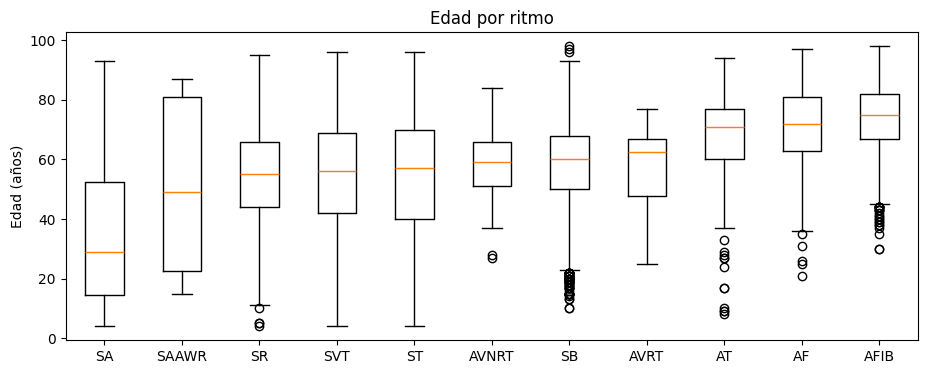

Kruskal-Wallis: H = 2221.3, p = 0


In [8]:
def resumen_edad(df):
    """Edad media, mediana, mínima y máxima de cada ritmo, ordenada por la mediana."""
    tabla = df.groupby("Rhythm")["PatientAge"].agg(["count", "mean", "median", "min", "max"])
    return tabla.sort_values("median").round(1)


tabla_edad = resumen_edad(df)
print(tabla_edad)

# Diagrama de cajas: una caja por ritmo
edades = [df[df["Rhythm"] == r]["PatientAge"] for r in tabla_edad.index]
plt.figure(figsize=(11, 4))
plt.boxplot(edades)
plt.xticks(range(1, len(tabla_edad) + 1), tabla_edad.index)
plt.title("Edad por ritmo")
plt.ylabel("Edad (años)")
plt.show()

# Prueba de Kruskal-Wallis: ¿la edad es distinta entre los ritmos?
H, p = stats.kruskal(*edades)
print(f"Kruskal-Wallis: H = {H:.1f}, p = {p:.3g}")

In [9]:
def grupo_de_edad(edad):
    """Devuelve la década a la que pertenece una edad."""
    if edad < 20:
        return "<20"
    elif edad >= 90:
        return "90+"
    else:
        inicio = (edad // 10) * 10
        return f"{inicio}-{inicio + 9}"


df["GrupoEdad"] = df["PatientAge"].apply(grupo_de_edad)
tabla_grupos = pd.crosstab(df["GrupoEdad"], df["Rhythm"])
orden_grupos = ["<20", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80-89", "90+"]
tabla_grupos = tabla_grupos.loc[orden_grupos, tabla_prev.index]   # filas por edad, columnas por prevalencia
print("Número de pacientes por grupo de edad y ritmo:")
print(tabla_grupos)

print("\nRitmo más frecuente en cada grupo de edad:")
for grupo in tabla_grupos.index:
    fila = tabla_grupos.loc[grupo]
    print(f"  {grupo:6s} -> {fila.idxmax():5s} ({100 * fila.max() / fila.sum():.0f} % del grupo)")

Número de pacientes por grupo de edad y ritmo:
Rhythm       SB   SR  AFIB   ST  SVT   AF   SA  AT  AVNRT  AVRT  SAAWR
GrupoEdad                                                             
<20          30   30     0  102   11    0  136   6      0     0      2
20-29       122  117     0  134   44    3   64   5      2     1      1
30-39       231  205     8  139   62    4   50   2      1     0      0
40-49       519  304    52  196  109   26   41   5      0     2      1
50-59      1009  430   140  264  111   44   30  10      5     0      0
60-69      1206  409   395  319  115  104   36  26      5     3      0
70-79       564  231   575  218   63  136   29  44      0     2      1
80-89       195   93   538  177   56   96   11  16      3     0      2
90+          13    7    72   19   16   32    2   7      0     0      0

Ritmo más frecuente en cada grupo de edad:
  <20    -> SA    (43 % del grupo)
  20-29  -> ST    (27 % del grupo)
  30-39  -> SB    (33 % del grupo)
  40-49  -> SB    (41 %

**Respuesta.** Sí: la edad cambia mucho según el ritmo (Kruskal-Wallis, p < 0,001).
- **Irregularidad sinusal (SA):** es de pacientes jóvenes (mediana de 29 años) y es el ritmo más frecuente en menores de 20 años.
- **Taquicardia sinusal (ST):** es la más frecuente entre los 20 y 29 años.
- **Bradicardia sinusal (SB):** domina entre los 30 y 69 años.
- **Fibrilación auricular (AFIB) y flutter (AF):** son de pacientes mayores (medianas de 75 y 72 años). Desde los 70 años la AFIB es el ritmo más frecuente; entre los 80 y 89 años llega al 45 % de los pacientes.


### 2.4 ¿Qué rango de edades y arritmias usar para entrenar algoritmos?
Un algoritmo aprende mejor si cada clase tiene **muchos ejemplos** y si las clases son **comparables**, por ejemplo en edades parecidas.

**Regla usada:** se incluye un ritmo si tiene **al menos 50 pacientes en cada década** entre los 40 y los 89 años.


In [10]:
def ritmos_suficientes(tabla_grupos, decadas, minimo=50):
    """Ritmos que tienen al menos 'minimo' pacientes en cada una de las décadas indicadas."""
    seleccion = []
    for ritmo in tabla_grupos.columns:
        if (tabla_grupos.loc[decadas, ritmo] >= minimo).all():
            seleccion.append(ritmo)
    return seleccion


decadas = ["40-49", "50-59", "60-69", "70-79", "80-89"]
print(tabla_grupos.loc[decadas])
ritmos_sel = ritmos_suficientes(tabla_grupos, decadas)
print("\nRitmos seleccionados:", ritmos_sel)

Rhythm       SB   SR  AFIB   ST  SVT   AF  SA  AT  AVNRT  AVRT  SAAWR
GrupoEdad                                                            
40-49       519  304    52  196  109   26  41   5      0     2      1
50-59      1009  430   140  264  111   44  30  10      5     0      0
60-69      1206  409   395  319  115  104  36  26      5     3      0
70-79       564  231   575  218   63  136  29  44      0     2      1
80-89       195   93   538  177   56   96  11  16      3     0      2

Ritmos seleccionados: ['SB', 'SR', 'AFIB', 'ST', 'SVT']


In [11]:
# Subconjunto: ritmos seleccionados y edades entre 40 y 89 años
sub = df[df["Rhythm"].isin(ritmos_sel) & (df["PatientAge"] >= 40) & (df["PatientAge"] <= 89)]

print("Pacientes en el subconjunto:", len(sub))
print(sub["Rhythm"].value_counts())
print("\nEdad media por ritmo:")
print(sub.groupby("Rhythm")["PatientAge"].mean().round(1))

# Se guarda para el punto 3 (compañero) y los puntos siguientes
sub.to_csv("subconjunto_punto2.csv", index=False)

Pacientes en el subconjunto: 8288
Rhythm
SB      3493
AFIB    1700
SR      1467
ST      1174
SVT      454
Name: count, dtype: int64

Edad media por ritmo:
Rhythm
AFIB    72.8
SB      61.3
SR      60.1
ST      63.6
SVT     61.2
Name: PatientAge, dtype: float64


**Respuesta.**
- **Rango de edad: 40 a 89 años.** Por debajo de 40 años casi no hay AFIB, y por encima de 90 hay muy pocos pacientes.
- **Ritmos: SB, SR, AFIB, ST y SVT.** Son los únicos que cumplen la regla.
- **Ritmos que quedan fuera:**
  - AF tiene solo 26 pacientes entre 40 y 49 años;
  - SA es casi solo de jóvenes;
  - AT, AVNRT, AVRT y SAAWR tienen muy pocos pacientes.
- El subconjunto tiene **8.288 pacientes** y se guarda en `subconjunto_punto2.csv`. Este archivo lo usa el punto 3.


### 2.5 ¿Coinciden la literatura y la base de datos?

| Base de datos | Literatura | ¿Coincide? |
|---|---|---|
| SB es el ritmo más frecuente, seguido de SR, AFIB y ST | Zheng *et al.* (2020), con la versión grande de esta misma base, encuentra el mismo orden: SB 38,6 %, SR 18,1 %, AFIB 17,5 %, ST 15,4 % | Sí |
| La AFIB aumenta con la edad (mediana de 75 años) | La fibrilación auricular pasa de 0,1 % en menores de 49 años a 13–18 % en mayores de 80 [Kavousi 2020]. Gadaleta *et al.* (2023) reporta 2,2 % en menores de 65 y 6,5 % en mayores de 65 | Sí |
| La AFIB tiene más hombres (58,5 %) | La fibrilación auricular es más frecuente en hombres [Kavousi 2020; Bernal y Moro 2006] | Sí |
| La SVT y la AVNRT tienen más mujeres | La AVNRT es cerca de 2 veces más frecuente en mujeres [Bernal y Moro 2006] | Sí |
| La SB tiene más hombres | Los hombres tienen menor frecuencia cardiaca en reposo [Bernal y Moro 2006] | Sí |
| La SA aparece sobre todo en jóvenes | Zheng *et al.* (2020) reporta una edad media de 37 años para la irregularidad sinusal, la menor de todos los ritmos | Sí |

**Conclusión.** En general **sí coinciden**. La diferencia está en el ritmo más frecuente: en la población general la arritmia sostenida más común es la fibrilación auricular, pero esta base viene de pacientes de dos hospitales, no de toda la población.

*Referencias:* Kavousi M. (2020) *Front. Cardiovasc. Med.* 7:3; Bernal O., Moro C. (2006) *Rev. Esp. Cardiol.* 59(6):609-618; Zheng J. *et al.* (2020) *Sci. Rep.* 10:2898; Gadaleta M. *et al.* (2023) *npj Digit. Med.* 6:229.


### 2.6 ¿Qué otros análisis se proponen?
1. **Analizar la columna `Beat`.** El 49 % de los pacientes tiene condiciones adicionales, como bloqueos de rama o extrasístoles. Zheng *et al.* mostraron que estas condiciones empeoran la clasificación.
2. **Comparar las mediciones del ECG entre ritmos.** Por ejemplo, la frecuencia ventricular, el QRS y el QTc, para verificar que las etiquetas sean coherentes; la SB debería tener una frecuencia menor de 60 lpm.
3. **Comparar el QTc entre hombres y mujeres.**
4. **Estudiar la edad y el género juntos.** Por ejemplo, ver si el predominio de hombres en la AFIB se mantiene en todas las edades.
5. **Agrupar los ritmos en 4 clases** (SB, AFIB, taquicardias supraventriculares y SR), como hace Zheng *et al.*, para reducir el desbalance.


# Punto 3: fórmulas 1 a 4 de Kotriwar et al. (2018) y biespectro

Referencia: Kotriwar, Kachhara, Harikrishnan y Ambika, *Higher order spectral analysis of ECG signals*, arXiv:1809.08451.

Las cuatro fórmulas del artículo son:

1. Desviación por *detrending* polinomial, $\delta(n)$, para escoger el grado del polinomio.
2. Compresión (normalización min-máx) de la señal a $[0, 1]$.
3. Biespectro $b(f_1, f_2)$ promediado sobre $N$ segmentos.
4. Bicoherencia $B(f_1, f_2)$, el biespectro normalizado entre 0 y 1.

Se trabaja sobre la derivación II de los registros de `ECGDataDenoised` que están en el subconjunto del punto 2.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal

FS = 500                                   # Hz, Chapman-Shaoxing (10 s -> 5000 muestras)
RUTA_SENALES = Path("ECGDataDenoised")     # carpeta con los .csv de las señales (ajustar)
RUTA_SUBCONJUNTO = Path("subconjunto_punto2.csv")
DERIVACION_II = 1                          # columnas: I, II, III, aVR, aVL, aVF, V1..V6

In [13]:
def cargar_ecg(ruta_csv, derivacion=DERIVACION_II):
    # Siempre devuelve un vector 1-D (evita arrastrar formas viejas entre celdas)
    try:
        datos = pd.read_csv(ruta_csv, header=None).to_numpy(dtype=float)
    except ValueError:                     # por si el archivo trae encabezado
        datos = pd.read_csv(ruta_csv).to_numpy(dtype=float)
    x = np.asarray(datos[:, derivacion], dtype=float).ravel()
    if not np.all(np.isfinite(x)) or np.ptp(x) == 0:
        raise ValueError(f"Señal vacía, constante o con NaN: {ruta_csv}")
    return x

## Fórmula 1 — desviación por *detrending* polinomial

Se ajusta un polinomio de grado $n$ a la señal original $x^{(0)}$ y se resta, obteniendo la señal sin tendencia $x^{(n)}$. La desviación entre ambas es

$$\delta(n) = \frac{1}{k}\sum_{i=1}^{k}\left(x^{(0)}(i) - x^{(n)}(i)\right)^2$$

donde $k$ es la longitud de la señal. Se calcula para varios grados y se escoge el grado a partir del cual $\delta(n)$ se satura (los autores encontraron $n = 20$ en registros de 60 s).

**Cuidado al trasladarlo a Chapman.** Los registros duran 10 s, no 60 s. Un polinomio de grado alto en una ventana corta ya no solo sigue la deriva lenta: empieza a seguir la propia frecuencia cardíaca. Se comprobó con senoidales puras de 10 s a 500 Hz:

| Frecuencia | Grado 5 | Grado 10 | Grado 20 |
|---|---|---|---|
| 0.3 Hz (deriva) | 18 % | 97 % | 100 % |
| 0.5 Hz | 11 % | 30 % | 100 % |
| 1.0 Hz (pulso) | 4 % | 5 % | 27 % |
| 1.2 Hz | 3 % | 4 % | 14 % |

Esto es potencia eliminada por el ajuste. Con grado 20 se pierde más de una cuarta parte de la componente de 1 Hz, justo la frecuencia de pulso que se busca en el punto 4. Por eso aquí la curva $\delta(n)$ se usa para elegir el grado, pero con un tope de 10. Además, las señales de `ECGDataDenoised` ya pasaron por un LOESS que quitó la línea base, así que se espera una curva casi plana.

`np.polynomial.Polynomial.fit` reescala el eje temporal internamente; `np.polyfit` con grados altos sobre 5000 puntos es numéricamente inestable.

In [14]:
def detrend_polinomial(x, n):
    # Devuelve (señal sin tendencia, tendencia ajustada)
    t = np.arange(len(x))
    tendencia = np.polynomial.Polynomial.fit(t, x, deg=n)(t)
    return x - tendencia, tendencia


def delta_n(x, n):
    # Ec. (1): delta(n) = (1/k) * sum (x0(i) - xn(i))^2
    xn, _ = detrend_polinomial(x, n)
    return np.mean((x - xn) ** 2)


def curva_delta(x, grados=range(0, 21)):
    grados = np.array(list(grados))
    return grados, np.array([delta_n(x, n) for n in grados])


def elegir_grado(grados, deltas, tol=0.01, grado_max=10):
    # Primer grado en el que delta(n) cambia menos de tol (relativo) respecto al anterior, con tope
    cambio = np.abs(np.diff(deltas)) / np.maximum(deltas[1:], np.finfo(float).eps)
    estables = np.where(cambio < tol)[0]
    g = grados[estables[0] + 1] if len(estables) else grados[-1]
    return int(min(g, grado_max))

## Fórmula 2 — compresión

$$s(t_k) = \frac{x(t_k) - x_{\min}}{x_{\max} - x_{\min}}$$

Lleva todas las señales al intervalo $[0, 1]$ para compararlas sin sesgo por amplitud. Es la misma idea que el escalado min-máx de Zheng et al. (2020). La compresión no cambia la forma de la bicoherencia (que es adimensional), pero sí las potencias absolutas del espectro.

In [15]:
def compresion(x):
    # Ec. (2): s = (x - xmin) / (xmax - xmin)
    rango = np.max(x) - np.min(x)
    if rango == 0:
        raise ValueError("Señal constante: no se puede comprimir")
    return (x - np.min(x)) / rango

## Fórmulas 3 y 4 — biespectro y bicoherencia

La señal se divide en $N$ segmentos y se calcula la transformada de Fourier $X_j(f)$ de cada uno.

$$b(f_1, f_2) = \sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2) \qquad \text{(3)}$$

$$B(f_1, f_2) = \frac{\left|\sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2)\right|}{\sum_{j=1}^{N}\left|X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2)\right|} \qquad \text{(4)}$$

Por simetría basta la región $f_2 > 0$, $f_1 \ge f_2$, $f_1 + f_2 \le f_{\text{Nyquist}}$. Como el artículo, se calcula para $f_1, f_2 \le 20$ Hz, donde está casi toda la potencia del ECG.

**Elección de parámetros para registros de 10 s.** El artículo usó segmentos de 8192 muestras sobre 60 s a 1000 Hz; aquí eso es imposible. Hay un compromiso:

- El umbral de significancia es $\sqrt{9.2 / (2N)}$ y la bicoherencia de la ec. (4) nunca supera 1. Con $N < 5$ el umbral queda por encima de 1 y ningún par puede ser significativo. Con $N = 5$ (segmentos de 2 s) el umbral es 0.96, casi inalcanzable.
- Segmentos de 500 muestras (1 s) dan $N = 10$ y umbral 0.678, a costa de una resolución nativa de 1 Hz. Se rellena con ceros a `nfft = 1024` para tener una rejilla de 0.49 Hz (esto interpola el espectro, no mejora la resolución real).

Se usa ventana de Hann para reducir la fuga espectral (el artículo no especifica ventana; `ventana="boxcar"` reproduce la FFT sin ventana) y se quita la media de cada segmento para que la componente DC no domine.

In [16]:
def segmentar(x, nperseg, solape=0):
    paso = nperseg - solape
    n_seg = 1 + (len(x) - nperseg) // paso
    idx = np.arange(nperseg)[None, :] + paso * np.arange(n_seg)[:, None]
    return x[idx]                                   # (N, nperseg)


def fft_segmentos(x, fs=FS, nperseg=500, nfft=1024, ventana="hann"):
    seg = segmentar(np.asarray(x, dtype=float).ravel(), nperseg)
    seg = seg - seg.mean(axis=1, keepdims=True)
    w = signal.get_window(ventana, nperseg)
    X = np.fft.rfft(seg * w, n=nfft, axis=1)        # X_j(f) por segmento
    f = np.fft.rfftfreq(nfft, d=1 / fs)
    return f, X


def biespectro_bicoherencia(x, fs=FS, nperseg=500, nfft=1024, fmax=20, ventana="hann"):
    # Ec. (3) y (4). Devuelve f, b (complejo), B en [0,1], N y la máscara de la región no redundante
    f, X = fft_segmentos(x, fs, nperseg, nfft, ventana)
    N = X.shape[0]
    k = np.searchsorted(f, fmax, side="right")
    i = np.arange(k)
    K1, K2 = np.meshgrid(i, i, indexing="ij")              # K1 -> f1 (filas), K2 -> f2 (columnas)
    triple = X[:, K1] * X[:, K2] * np.conj(X[:, K1 + K2])   # (N, k, k)
    b = triple.sum(axis=0)                                  # ec. (3)
    denom = np.abs(triple).sum(axis=0)
    B = np.divide(np.abs(b), denom, out=np.zeros_like(denom), where=denom > 0)   # ec. (4)
    region = (K2 > 0) & (K1 >= K2)
    return f[:k], b, B, N, region


def umbral_bicoherencia(N):
    # N = número de SEGMENTOS promediados, no número de muestras
    return np.sqrt(9.2 / (2 * N))

## Validación con una señal sintética



Acoplada     B(5,3) = 1.000   umbral = 0.678
No acoplada  B(5,3) = 0.400   umbral = 0.678


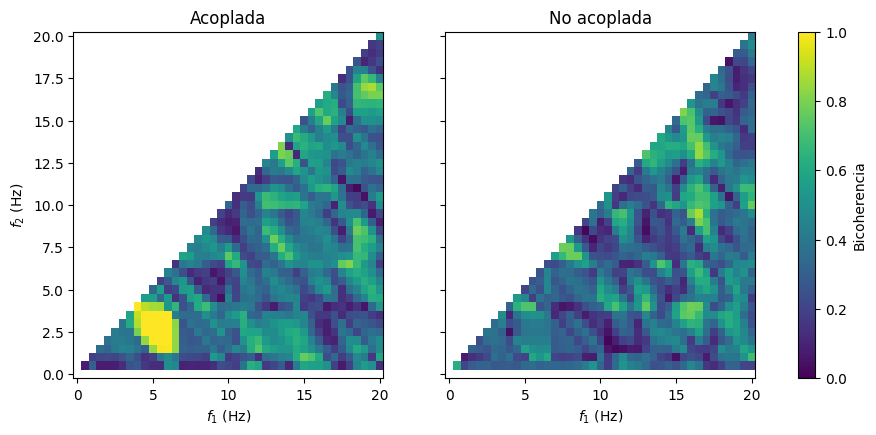

In [17]:
rng = np.random.default_rng(0)
t = np.arange(500) / FS

def sintetica(acoplada, n_seg=10):
    segs = []
    for _ in range(n_seg):
        p1, p2, p3 = rng.uniform(0, 2 * np.pi, 3)
        p3 = p1 + p2 if acoplada else p3
        segs.append(np.cos(2*np.pi*5*t + p1) + np.cos(2*np.pi*3*t + p2)
                    + np.cos(2*np.pi*8*t + p3) + 0.3 * rng.standard_normal(t.size))
    return np.concatenate(segs)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for eje, acoplada in zip(ejes, (True, False)):
    f, b, B, N, region = biespectro_bicoherencia(sintetica(acoplada), nfft=1000)
    i5, i3 = np.argmin(abs(f - 5)), np.argmin(abs(f - 3))
    print(f"{'Acoplada' if acoplada else 'No acoplada':12s} B(5,3) = {B[i5, i3]:.3f}   umbral = {umbral_bicoherencia(N):.3f}")
    im = eje.pcolormesh(f, f, np.where(region, B, np.nan).T, vmin=0, vmax=1, shading="auto")
    eje.set_title("Acoplada" if acoplada else "No acoplada")
    eje.set_xlabel("$f_1$ (Hz)")
ejes[0].set_ylabel("$f_2$ (Hz)")
fig.colorbar(im, ax=ejes, label="Bicoherencia")
plt.show()

In [18]:
rng_ruido = np.random.default_rng(1)
tasas = []
for _ in range(50):
    f, b, B, N, region = biespectro_bicoherencia(rng_ruido.standard_normal(5000))
    tasas.append((B[region] > umbral_bicoherencia(N)).mean())
print(f"Pares evaluados: {region.sum()}   Falsos positivos en ruido blanco: {100*np.mean(tasas):.1f} %"
      f"  (~{np.mean(tasas)*region.sum():.0f} pares por señal)")

Pares evaluados: 820   Falsos positivos en ruido blanco: 7.2 %  (~59 pares por señal)


## Aplicación a señales del subconjunto del punto 2

Se toma un registro al azar de cada ritmo del subconjunto y se aplica la cadena completa: curva $\delta(n)$ → *detrending* con el grado elegido → compresión → bicoherencia.

In [19]:
subconjunto = pd.read_csv(RUTA_SUBCONJUNTO)
print(subconjunto["Rhythm"].value_counts())

def procesar_registro(nombre, grados=range(0, 21)):
    x = cargar_ecg(RUTA_SENALES / f"{nombre}.csv")
    g, d = curva_delta(x, grados)
    n = elegir_grado(g, d)
    x_det, _ = detrend_polinomial(x, n)
    s = compresion(x_det)
    f, b, B, N, region = biespectro_bicoherencia(s)
    return dict(x=x, grados=g, deltas=d, n=n, s=s, f=f, b=b, B=B, N=N, region=region)

def primer_valido(grupo, semilla=42):
    for nombre in grupo.sample(frac=1, random_state=semilla)["FileName"]:
        try:
            return nombre, procesar_registro(nombre)
        except ValueError as e:
            print("  Se omite:", e)
    return None, None

resultados = {}
for ritmo, grupo in subconjunto.groupby("Rhythm"):
    nombre, r = primer_valido(grupo)
    if r is not None:
        resultados[ritmo] = r
        print(f"{ritmo}: {nombre}")

Rhythm
SB      3493
AFIB    1700
SR      1467
ST      1174
SVT      454
Name: count, dtype: int64
AFIB: MUSE_20180113_122043_40000
SB: MUSE_20180112_134027_79000
SR: MUSE_20180113_125854_77000
ST: MUSE_20180112_075431_42000
SVT: MUSE_20180712_151222_03000


In [20]:
"""cabe aclarar que si el archivo de algun 
paciente tiene valores faltantes o NaNel proceso se detiene"""
#ejemplo de un paciente que tenia valores faltantes 
ruta_mala = RUTA_SENALES / "MUSE_20181222_204131_50000.csv"
datos = pd.read_csv(ruta_mala, header=None).to_numpy(dtype=float)
print("Forma:", datos.shape)
print("NaN por derivación:", np.isnan(datos).sum(axis=0))
print("Rango por derivación:", np.round(np.nanmax(datos, axis=0) - np.nanmin(datos, axis=0), 2))

Forma: (5000, 12)
NaN por derivación: [0 0 0 0 0 0 0 0 0 0 0 0]
Rango por derivación: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


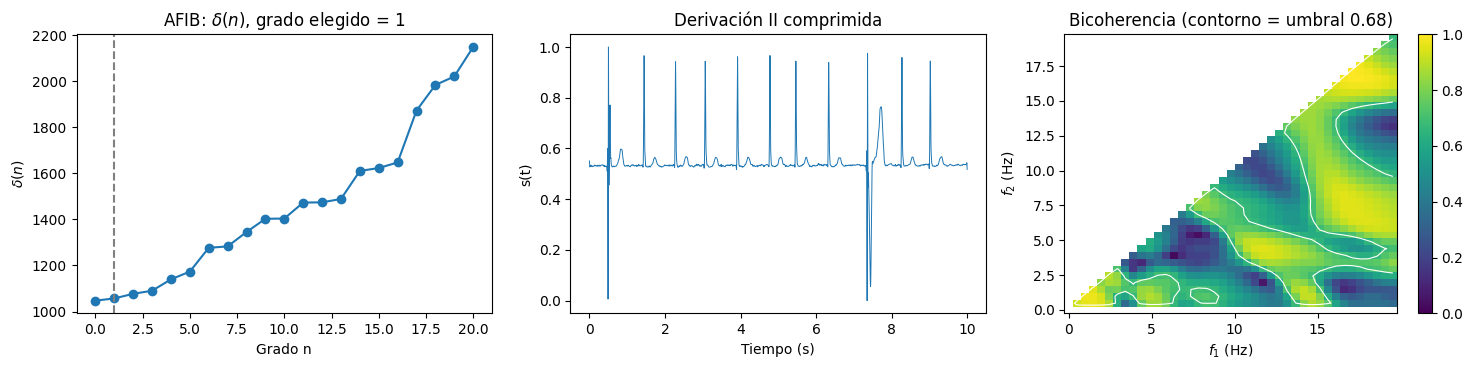

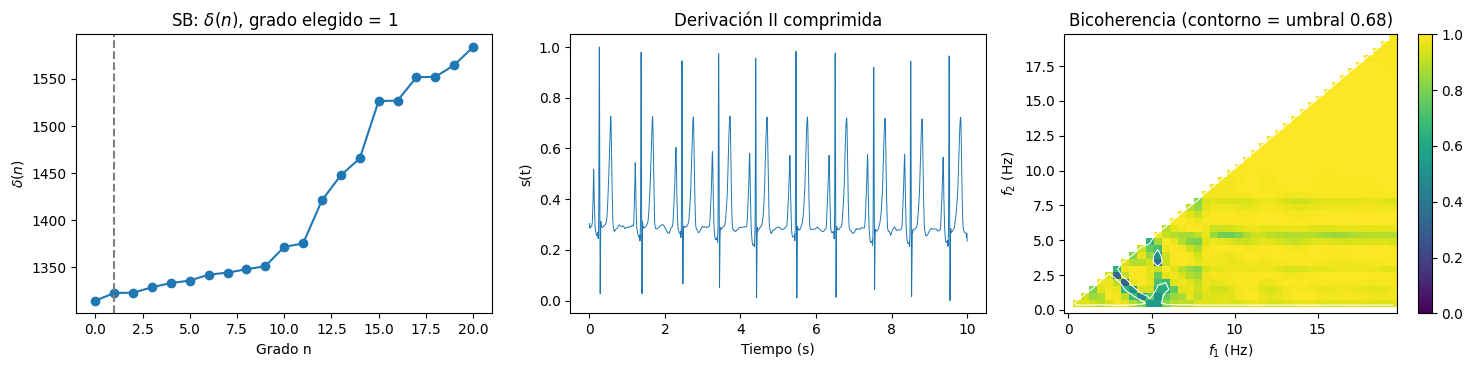

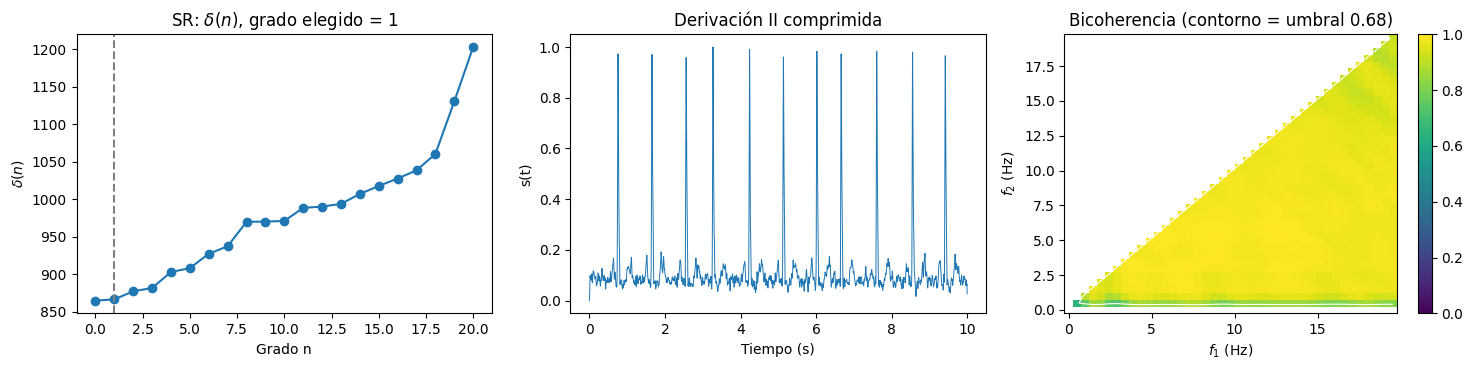

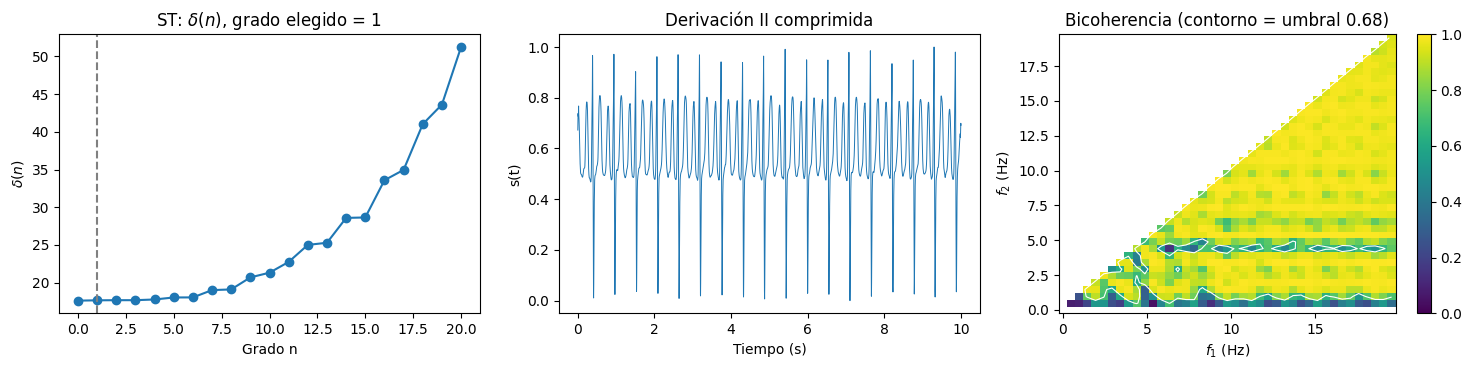

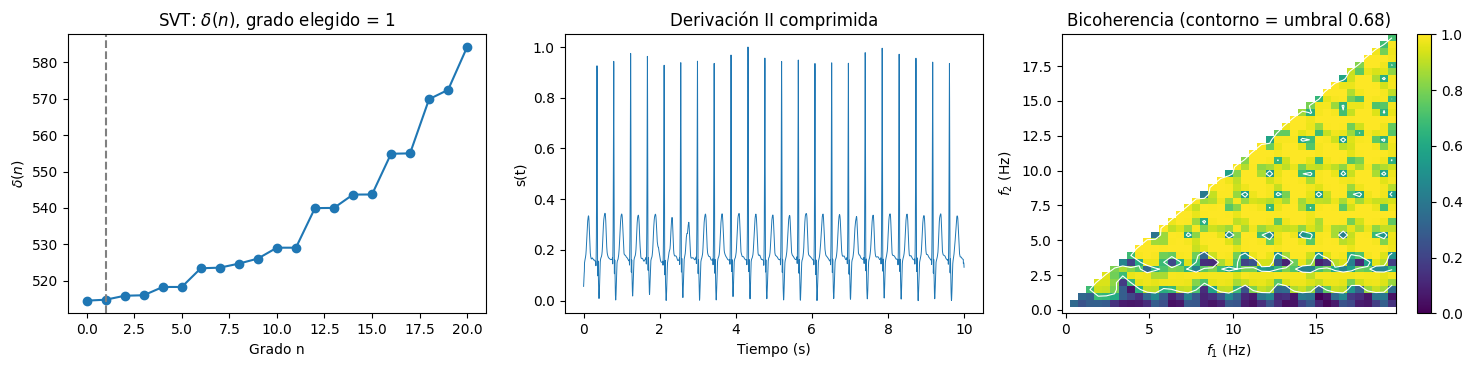

In [21]:
for ritmo, r in resultados.items():
    fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
    ejes[0].plot(r["grados"], r["deltas"], "o-")
    ejes[0].axvline(r["n"], ls="--", c="gray")
    ejes[0].set(title=f"{ritmo}: $\\delta(n)$, grado elegido = {r['n']}", xlabel="Grado n", ylabel="$\\delta(n)$")
    tt = np.arange(r["s"].size) / FS
    ejes[1].plot(tt, r["s"], lw=0.7)
    ejes[1].set(title="Derivación II comprimida", xlabel="Tiempo (s)", ylabel="s(t)")
    u = umbral_bicoherencia(r["N"])
    im = ejes[2].pcolormesh(r["f"], r["f"], np.where(r["region"], r["B"], np.nan).T, vmin=0, vmax=1, shading="auto")
    ejes[2].contour(r["f"], r["f"], np.where(r["region"], r["B"], 0).T, levels=[u], colors="w", linewidths=0.8)
    ejes[2].set(title=f"Bicoherencia (contorno = umbral {u:.2f})", xlabel="$f_1$ (Hz)", ylabel="$f_2$ (Hz)")
    fig.colorbar(im, ax=ejes[2])
    plt.tight_layout()
    plt.show()

## Significado y utilidad del biespectro

**Qué es.** El espectro de potencia es la transformada de Fourier de la autocorrelación (estadística de segundo orden): dice cuánta energía hay en cada frecuencia, pero descarta las fases. El biespectro es la transformada de Fourier de la correlación de tercer orden, $E[x(t)\,x(t+\tau_1)\,x(t+\tau_2)]$, y es una función de dos frecuencias. Su valor en $(f_1, f_2)$ es grande cuando existe una componente en $f_1 + f_2$ cuya fase está ligada a las de $f_1$ y $f_2$ ($\varphi_3 = \varphi_1 + \varphi_2$) de forma consistente entre segmentos. Eso se llama acoplamiento cuadrático de fase.

**Por qué importa.** Un sistema lineal no crea frecuencias nuevas: si entran $f_1$ y $f_2$, salen $f_1$ y $f_2$. Un sistema no lineal (por ejemplo, con un término cuadrático) genera $f_1 + f_2$ y $f_1 - f_2$ con fases amarradas a las originales. Por tanto, el biespectro distingue dos señales que tienen el mismo espectro de potencia: una cuyos picos son armónicos generados por la misma dinámica y otra cuyos picos son componentes independientes o ruido. Además, para un proceso gaussiano el biespectro es cero, así que también mide desviación de la gaussianidad.

**Bicoherencia.** El biespectro depende de la amplitud de la señal; la bicoherencia lo normaliza entre 0 (fases sin relación) y 1 (acoplamiento perfecto), lo que permite comparar registros y aplicar un umbral de significancia.

**Utilidad en ECG.** El latido produce una frecuencia fundamental (frecuencia de pulso, cerca de 1 Hz) y armónicos generados por la forma no sinusoidal del complejo P-QRS-T. En un corazón sano esos armónicos están acoplados en fase con el pulso. Kotriwar et al. encontraron que en sujetos sanos el pulso tiene acoplamiento significativo con muchas frecuencias, mientras que en patologías ese acoplamiento se pierde o aparecen frecuencias de potencia alta sin acoplamiento, que sugieren ruido o procesos estocásticos. En arritmias como la fibrilación auricular, donde la activación auricular es desorganizada y los intervalos RR son irregulares, se espera una estructura de bicoherencia distinta a la del ritmo sinusal. Esa diferencia es la que se cuantifica en los puntos 5 a 8. Otras aplicaciones del análisis biespectral incluyen EEG (por ejemplo, el índice biespectral de profundidad anestésica), detección de fallas en maquinaria y análisis de oleaje.

---
## Punto 4. Frecuencia de máxima potencia (fMP)

**Qué se hace:**
1. Se toma la señal y se preprocesa con las **funciones del punto 3**, en este orden:
   - se elige el grado del polinomio con la curva δ(n);
   - se quita la tendencia;
   - se comprime la señal entre 0 y 1.
2. Se calcula el **espectro de potencia** con el método de Welch, que es el que usa el artículo. Se usan ventanas de 5 s, lo que da una resolución de 0,2 Hz.
3. La **fMP** es la frecuencia donde el espectro es más alto.


In [22]:
from scipy.signal import welch


def preprocesar(x):
    """Ecuaciones 1 y 2 usando las funciones del punto 3."""
    grados, deltas = curva_delta(x)
    n = elegir_grado(grados, deltas)
    x_sin_tendencia, _ = detrend_polinomial(x, n)
    return compresion(x_sin_tendencia)


def espectro_potencia(s, fs=FS):
    """Espectro de potencia por el método de Welch (ventanas de 5 s)."""
    f, P = welch(s - np.mean(s), fs=fs, nperseg=2500)
    return f, P


def calcular_fmp(s, fs=FS):
    """Frecuencia de máxima potencia: la frecuencia donde P es máximo."""
    f, P = espectro_potencia(s, fs)
    return f[np.argmax(P)]

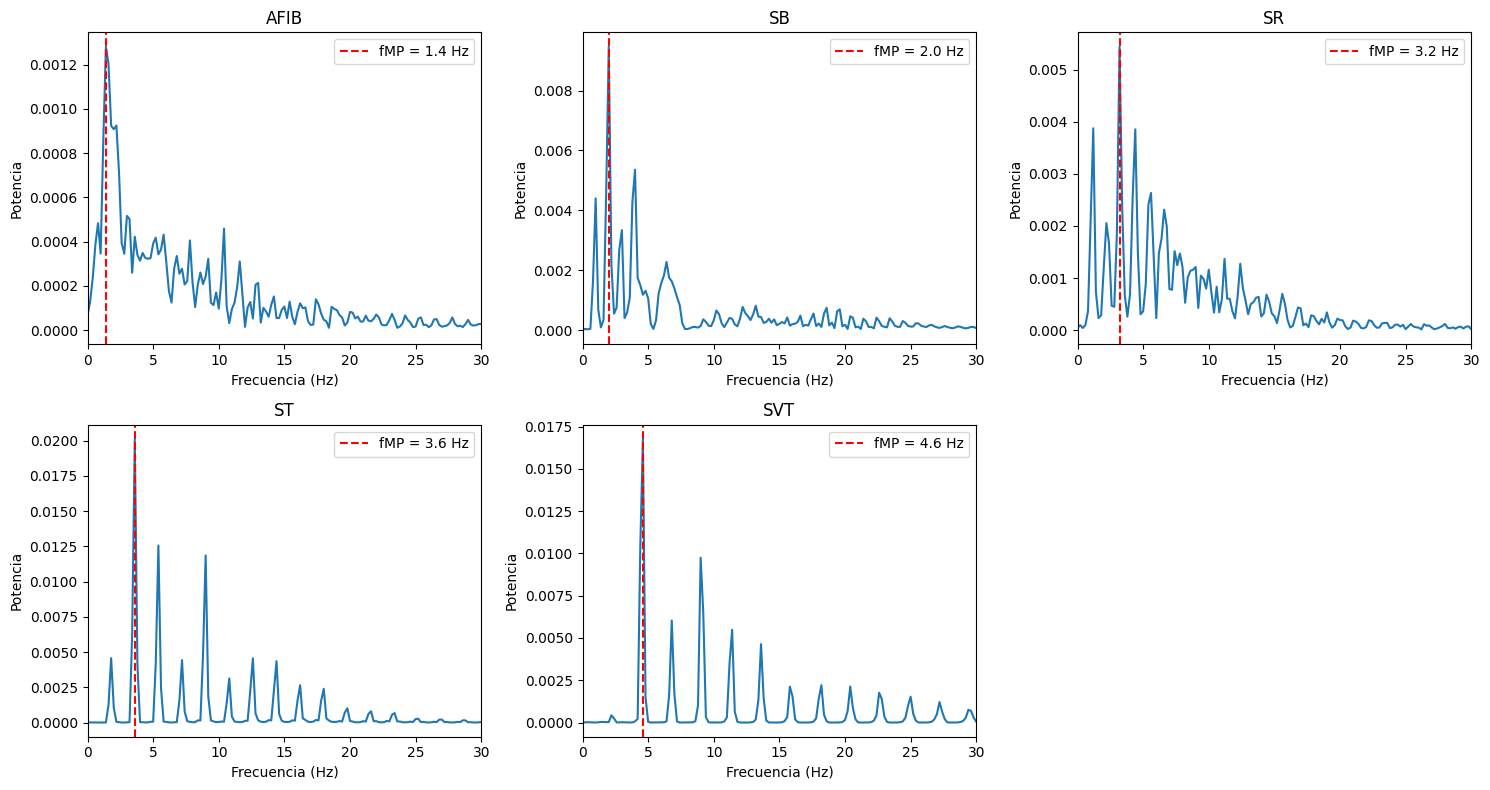

In [23]:
plt.figure(figsize=(15, 8))
i = 1
for ritmo in resultados:                  # 'resultados' es el diccionario del punto 3: un registro por ritmo
    s = resultados[ritmo]["s"]            # señal ya preprocesada en el punto 3
    f, P = espectro_potencia(s)
    fmp = calcular_fmp(s)

    plt.subplot(2, 3, i)
    plt.plot(f, P)
    plt.axvline(fmp, color="red", linestyle="--", label=f"fMP = {fmp:.1f} Hz")
    plt.xlim(0, 30)
    plt.title(ritmo)
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Potencia")
    plt.legend()
    i = i + 1
plt.tight_layout()
plt.show()